# Actividad 09 (Unidad II) — PCA, NMF y detección de anomalías

**Universidad Nacional del Altiplano - Puno**  
Ingeniería de Sistemas · Maestría en Ciencia de Datos  

**Curso:** Machine Learning I - Grupo A  

**Presentado por:**  
- Darwin Rigoberto Mamani Quispe  
- Melbis Chino Huaycani  

## Objetivo
Comprender el uso de la reducción de dimensiones y la detección de anomalías mediante tres aplicaciones:

1. Reconocimiento de rostros con **Eigenfaces (PCA)**.
2. Recomendación de artículos mediante **NMF + similitud de coseno**.
3. Detección de anomalías en series temporales mediante un **ensemble**.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA, NMF
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor, NearestNeighbors

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# A. Sistema de reconocimiento de rostros basado en Eigenfaces

## 1. Planteamiento

El dataset **Olivetti Faces** contiene imágenes de rostros en escala de grises. Cada imagen de 64×64 píxeles puede verse como un vector de 4096 características.

Trabajar directamente con 4096 variables es innecesariamente costoso. Por ello se aplica **PCA** para obtener un espacio de menor dimensión. En reconocimiento facial, los componentes principales aprendidos reciben el nombre de **Eigenfaces**.

El procedimiento será:

**Olivetti Faces → división entrenamiento/prueba → PCA → Eigenfaces → clasificador SVM → evaluación**

No se utilizan redes neuronales.

In [2]:
from sklearn.datasets import fetch_olivetti_faces

faces = fetch_olivetti_faces(shuffle=True, random_state=RANDOM_STATE)

X = faces.data
y = faces.target
images = faces.images

print("Forma de X:", X.shape)
print("Forma de las imágenes:", images.shape)
print("Número de personas:", len(np.unique(y)))
print("Número de imágenes:", len(X))

downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to /home/darig/scikit_learn_data
Forma de X: (400, 4096)
Forma de las imágenes: (400, 64, 64)
Número de personas: 40
Número de imágenes: 400


### Exploración del dataset

Antes de entrenar el modelo se visualizan algunas imágenes para comprobar la estructura de los datos y sus etiquetas.

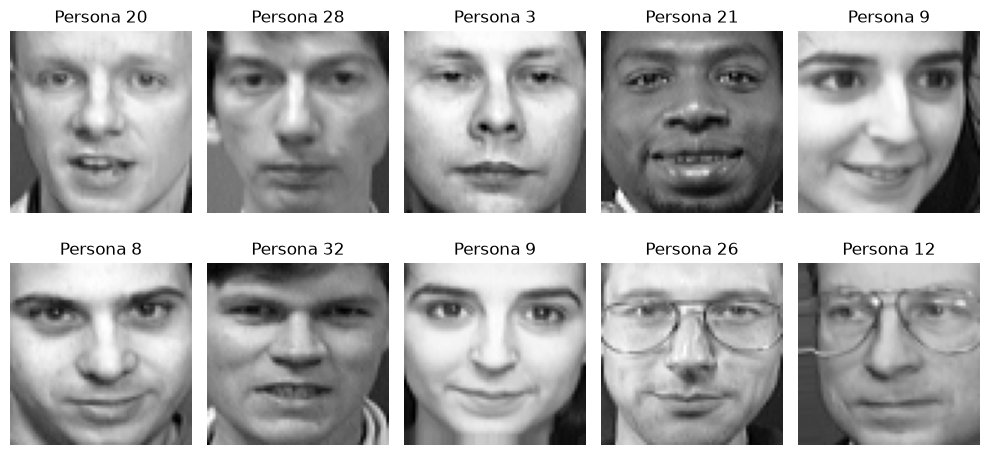

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(10, 5))
for ax, image, label in zip(axes.ravel(), images[:10], y[:10]):
    ax.imshow(image, cmap="gray")
    ax.set_title(f"Persona {label}")
    ax.axis("off")
plt.tight_layout()
plt.show()

## 2. Separación de entrenamiento y prueba

Se conserva el 25 % de las imágenes para evaluación. Se utiliza `stratify=y` para mantener representación de las 40 personas en ambos subconjuntos.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Entrenamiento:", X_train.shape)
print("Prueba:", X_test.shape)

Entrenamiento: (300, 4096)
Prueba: (100, 4096)


## 3. PCA y Eigenfaces

PCA aprende las direcciones de mayor variabilidad de los rostros. Se utilizan **100 componentes**, reduciendo cada imagen desde 4096 píxeles hasta 100 características.

`whiten=True` normaliza la varianza de los componentes y suele ser útil antes del clasificador.

In [5]:
n_components = 100

pca = PCA(
    n_components=n_components,
    whiten=True,
    svd_solver="randomized",
    random_state=RANDOM_STATE
)

X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

print("Dimensión original:", X_train.shape[1])
print("Dimensión reducida:", X_train_pca.shape[1])
print("Varianza explicada acumulada:",
      round(pca.explained_variance_ratio_.sum(), 4))

Dimensión original: 4096
Dimensión reducida: 100
Varianza explicada acumulada: 0.9437


### Visualización de Eigenfaces

Cada componente de PCA puede reconstruirse como una imagen 64×64. Estas imágenes representan patrones de variación presentes en los rostros: zonas de iluminación, contornos, ojos, nariz y otras estructuras.

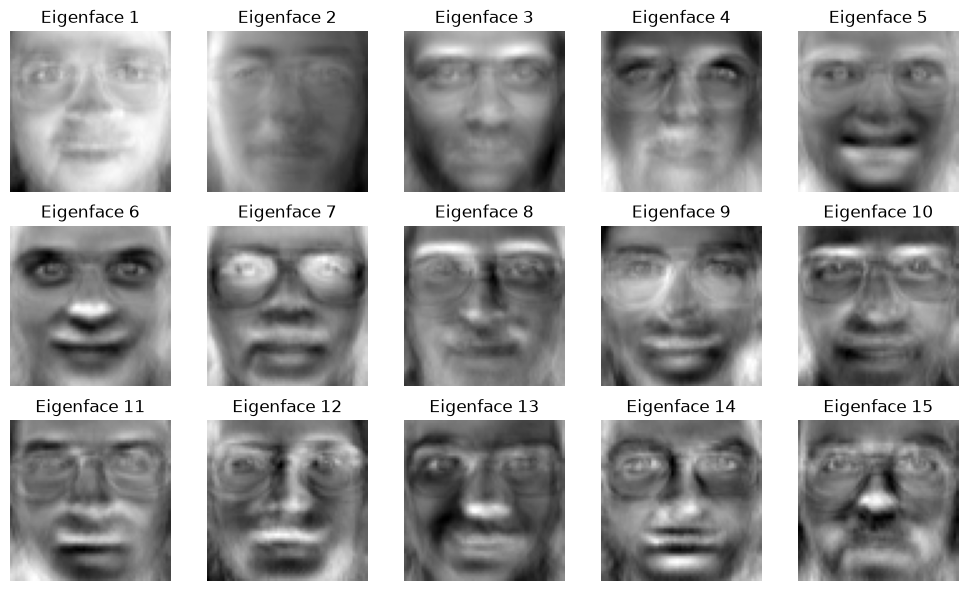

In [6]:
eigenfaces = pca.components_.reshape((n_components, 64, 64))

fig, axes = plt.subplots(3, 5, figsize=(10, 6))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(eigenfaces[i], cmap="gray")
    ax.set_title(f"Eigenface {i+1}")
    ax.axis("off")
plt.tight_layout()
plt.show()

## 4. Reconocimiento de rostros

Después de PCA se utiliza un **SVM** como clasificador. PCA se encarga de representar los rostros y SVM aprende a identificar a cuál de las 40 personas pertenece cada representación.

In [7]:
clf = SVC(kernel="rbf", C=10, gamma="scale")
clf.fit(X_train_pca, y_train)

y_pred = clf.predict(X_test_pca)

acc = accuracy_score(y_test, y_pred)
print(f"Accuracy: {acc:.4f}")
print("\nReporte de clasificación:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.9800

Reporte de clasificación:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         2
           1       1.00      1.00      1.00         3
           2       1.00      0.67      0.80         3
           3       0.75      1.00      0.86         3
           4       1.00      1.00      1.00         2
           5       1.00      1.00      1.00         3
           6       1.00      1.00      1.00         2
           7       1.00      1.00      1.00         3
           8       1.00      1.00      1.00         2
           9       1.00      1.00      1.00         2
          10       1.00      1.00      1.00         3
          11       1.00      1.00      1.00         3
          12       1.00      1.00      1.00         2
          13       1.00      1.00      1.00         2
          14       1.00      1.00      1.00         3
          15       1.00      1.00      1.00         2
          16       1.00      1.00    

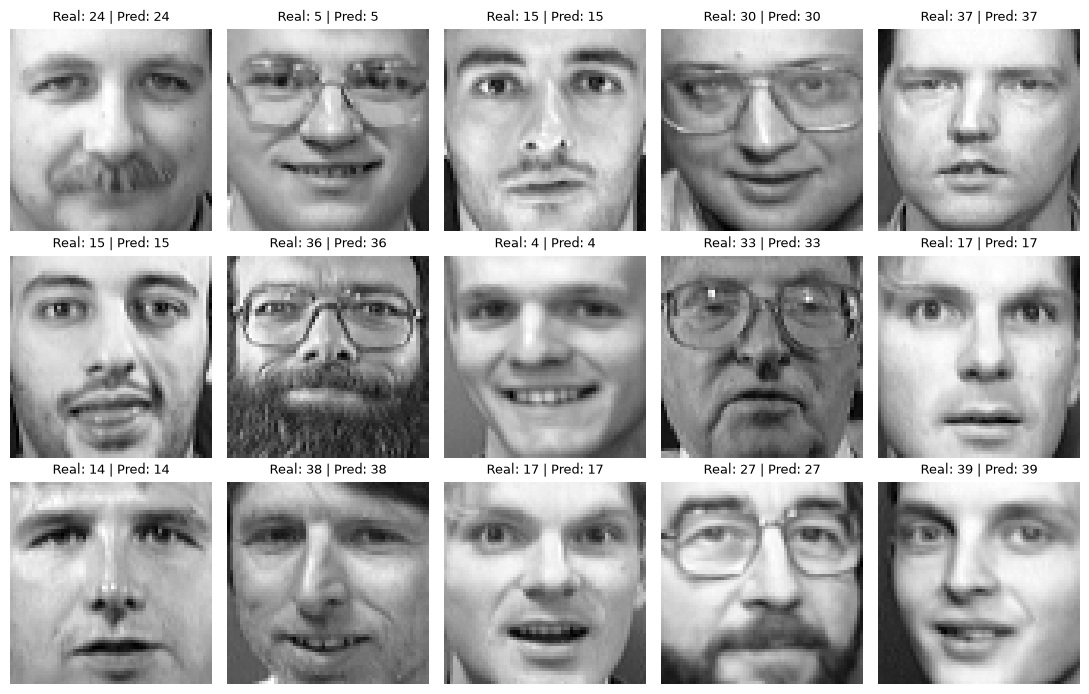

In [8]:
fig, axes = plt.subplots(3, 5, figsize=(11, 7))
for ax, x, real, pred in zip(axes.ravel(), X_test[:15], y_test[:15], y_pred[:15]):
    ax.imshow(x.reshape(64, 64), cmap="gray")
    ax.set_title(f"Real: {real} | Pred: {pred}",
                 fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

### Interpretación

El sistema no compara directamente los 4096 píxeles de cada imagen. Primero proyecta cada rostro sobre las Eigenfaces y obtiene una representación compacta. Posteriormente, el SVM realiza la identificación en ese nuevo espacio.

El `accuracy` obtenido al ejecutar el notebook indica la proporción de rostros del conjunto de prueba reconocidos correctamente. Las imágenes finales permiten revisar visualmente los aciertos y errores.

# B. Recomendación de artículos con NMF y similitud de coseno

## 1. Planteamiento

Se simula el caso de un periódico digital. Dado el artículo que un usuario está leyendo, se deben recomendar artículos con contenido temáticamente similar.

La solución sigue este flujo:

**Artículos → TF-IDF → NMF → representación temática → similitud de coseno → recomendaciones**

NMF resulta apropiado porque representa cada documento como una combinación no negativa de temas. La similitud de coseno permite comparar esas representaciones.

In [9]:
articulos = [
    ("Tecnología", "La inteligencia artificial generativa transforma el desarrollo de software y automatiza tareas de programación."),
    ("Tecnología", "Nuevos modelos de inteligencia artificial mejoran el análisis de datos y la productividad empresarial."),
    ("Tecnología", "Empresas tecnológicas incorporan aprendizaje automático para detectar fraudes y analizar grandes bases de datos."),
    ("Tecnología", "La computación en la nube y la inteligencia artificial impulsan nuevos servicios digitales."),
    ("Deportes", "El equipo de fútbol consiguió una victoria luego de un intenso partido por el campeonato nacional."),
    ("Deportes", "La selección prepara su próximo partido con nuevas estrategias de ataque y defensa."),
    ("Deportes", "El campeonato de fútbol entra en su etapa decisiva con varios equipos luchando por el título."),
    ("Deportes", "Los jugadores retomaron los entrenamientos antes de la siguiente fecha del torneo."),
    ("Salud", "Especialistas recomiendan actividad física frecuente para prevenir enfermedades cardiovasculares."),
    ("Salud", "Una alimentación equilibrada y el ejercicio ayudan a reducir el riesgo de obesidad y diabetes."),
    ("Salud", "Investigadores estudian nuevas estrategias para mejorar la prevención y atención de enfermedades."),
    ("Salud", "Dormir adecuadamente y mantener hábitos saludables favorece el bienestar físico y mental."),
    ("Economía", "El banco central analiza la inflación y mantiene vigilancia sobre el crecimiento de la economía."),
    ("Economía", "Los mercados financieros reaccionaron a los nuevos datos de inflación y empleo."),
    ("Economía", "La inversión privada y el consumo influyen en las perspectivas de crecimiento económico."),
    ("Economía", "Analistas evalúan el comportamiento del dólar, las tasas de interés y los precios."),
    ("Ciencia", "Astrónomos observan nuevas señales procedentes de galaxias lejanas mediante telescopios espaciales."),
    ("Ciencia", "Una misión espacial estudiará la superficie y composición de un planeta distante."),
    ("Ciencia", "Investigadores analizan imágenes del espacio para comprender la formación de estrellas y galaxias."),
    ("Ciencia", "El nuevo telescopio permitirá estudiar con mayor precisión planetas y objetos del universo.")
]

df_articulos = pd.DataFrame(articulos, columns=["categoria", "texto"])
df_articulos.index.name = "id"
df_articulos

,categoria,texto
id,,
0,Tecnología,La inteligencia artificial generativa transfor...
1,Tecnología,Nuevos modelos de inteligencia artificial mejo...
2,Tecnología,Empresas tecnológicas incorporan aprendizaje a...
3,Tecnología,La computación en la nube y la inteligencia ar...
4,Deportes,El equipo de fútbol consiguió una victoria lue...
5,Deportes,La selección prepara su próximo partido con nu...
6,Deportes,El campeonato de fútbol entra en su etapa deci...
7,Deportes,Los jugadores retomaron los entrenamientos ant...
8,Salud,Especialistas recomiendan actividad física fre...


## 2. Vectorización TF-IDF

TF-IDF asigna mayor importancia a términos representativos de cada documento y reduce el peso de palabras demasiado frecuentes.

In [10]:
vectorizer = TfidfVectorizer(
    stop_words=None,
    lowercase=True,
    max_df=0.95,
    min_df=1
)

tfidf = vectorizer.fit_transform(df_articulos["texto"])

print("Matriz TF-IDF:", tfidf.shape)

Matriz TF-IDF: (20, 161)


## 3. Extracción de temas con NMF

Se buscan cinco componentes porque el conjunto de ejemplo contiene cinco áreas temáticas principales. Cada fila de `W` representa un artículo y cada columna indica cuánto participa ese tema en el artículo.

In [11]:
n_topics = 5

nmf = NMF(
    n_components=n_topics,
    init="nndsvda",
    random_state=RANDOM_STATE,
    max_iter=1000
)

W = nmf.fit_transform(tfidf)
H = nmf.components_

print("Representación de artículos:", W.shape)
print("Componentes/temas:", H.shape)

Representación de artículos: (20, 5)
Componentes/temas: (5, 161)


In [12]:
feature_names = np.array(vectorizer.get_feature_names_out())

for topic_idx, topic in enumerate(H):
    top_words = feature_names[topic.argsort()[-8:][::-1]]
    print(f"Tema {topic_idx + 1}: {', '.join(top_words)}")

Tema 1: la, inteligencia, artificial, de, nuevos, el, en, nube
Tema 2: el, una, fútbol, por, campeonato, de, un, con
Tema 3: nuevas, para, investigadores, estrategias, enfermedades, la, galaxias, mejorar
Tema 4: los, del, siguiente, retomaron, entrenamientos, jugadores, fecha, antes
Tema 5: tecnológicas, empresas, detectar, analizar, bases, automático, incorporan, fraudes


## 4. Recomendación mediante similitud de coseno

La similitud de coseno toma valores cercanos a 1 cuando dos vectores apuntan en direcciones parecidas. Aquí se compara la representación NMF de un artículo con la de todos los demás.

In [13]:
similaridades = cosine_similarity(W)

def recomendar_articulos(indice_articulo, n=3):
    scores = similaridades[indice_articulo].copy()
    orden = np.argsort(scores)[::-1]
    orden = orden[orden != indice_articulo][:n]

    resultado = df_articulos.loc[orden, ["categoria", "texto"]].copy()
    resultado["similitud"] = scores[orden]
    return resultado

articulo_actual = 0

print("ARTÍCULO ACTUAL")
print(df_articulos.loc[articulo_actual, "texto"])
print("\nRECOMENDACIONES")
recomendar_articulos(articulo_actual, n=3)

ARTÍCULO ACTUAL
La inteligencia artificial generativa transforma el desarrollo de software y automatiza tareas de programación.

RECOMENDACIONES


,categoria,texto,similitud
id,,,
3,Tecnología,La computación en la nube y la inteligencia ar...,0.999947
1,Tecnología,Nuevos modelos de inteligencia artificial mejo...,0.972231
14,Economía,La inversión privada y el consumo influyen en ...,0.890811


### Interpretación

El recomendador no busca únicamente palabras idénticas. NMF transforma los artículos a un espacio de temas latentes y la similitud de coseno compara los artículos dentro de ese espacio.

Por ejemplo, un artículo relacionado con inteligencia artificial debería recibir como recomendaciones otros textos del bloque tecnológico porque comparten una composición temática similar.

# C. Ensemble para detectar anomalías en series temporales

## 1. Planteamiento

Un **ensemble** combina las puntuaciones de dos o más detectores para obtener una decisión más estable que la de un único modelo.

Siguiendo el enfoque visto en clase, se utilizarán tres detectores:

- **KNN:** anomalía basada en distancia a los vecinos.
- **LOF:** anomalía basada en densidad local.
- **Isolation Forest:** anomalía basada en aislamiento mediante árboles aleatorios.

Luego se normalizan las puntuaciones y se calcula su **media** para producir un único `ensemble_score`.

Para que el ejercicio sea completamente reproducible, se construye una serie temporal sintética con tendencia, estacionalidad, ruido y anomalías conocidas.

In [14]:
n = 365
fechas = pd.date_range("2025-01-01", periods=n, freq="D")
t = np.arange(n)

tendencia = 0.03 * t
estacionalidad = 8 * np.sin(2 * np.pi * t / 30)
ruido = np.random.normal(0, 1.5, n)

valor = 50 + tendencia + estacionalidad + ruido

# Anomalías artificiales conocidas
indices_anomalos = np.array([45, 96, 150, 221, 300, 340])
valor[indices_anomalos] += np.array([25, -28, 30, -25, 32, -30])

ts = pd.DataFrame({"fecha": fechas, "valor": valor})
ts["anomalia_real"] = 0
ts.loc[indices_anomalos, "anomalia_real"] = 1
ts = ts.set_index("fecha")

ts.head()

,valor,anomalia_real
fecha,,
2025-01-01,49.174648,0
2025-01-02,52.466443,0
2025-01-03,54.024684,0
2025-01-04,56.844957,0
2025-01-05,54.689918,0


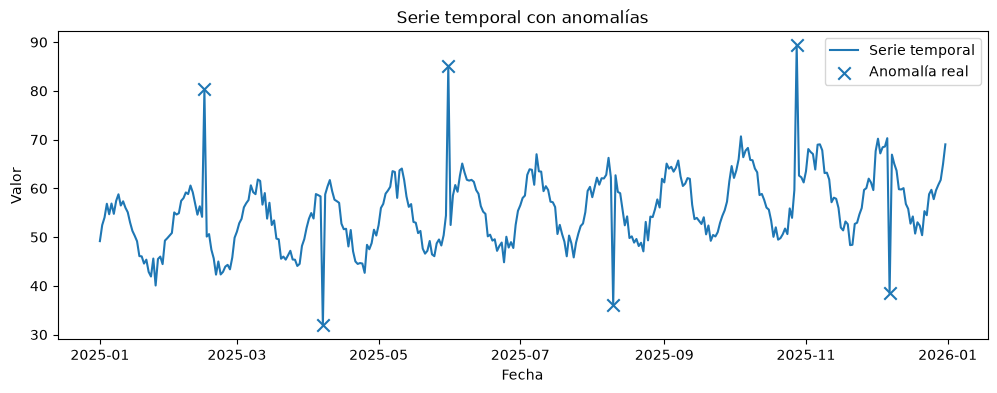

In [15]:
plt.figure(figsize=(12, 4))
plt.plot(ts.index, ts["valor"], label="Serie temporal")
plt.scatter(
    ts.index[ts["anomalia_real"] == 1],
    ts.loc[ts["anomalia_real"] == 1, "valor"],
    marker="x", s=80, label="Anomalía real"
)
plt.title("Serie temporal con anomalías")
plt.xlabel("Fecha")
plt.ylabel("Valor")
plt.legend()
plt.show()

## 2. Preparación de características

Además del valor actual se incorporan características simples de contexto temporal:

- cambio respecto al día anterior;
- media móvil de 7 días;
- desviación móvil de 7 días.

Esto permite que los detectores observen no solo el nivel de la serie, sino también cambios inusuales respecto a su comportamiento reciente.

In [16]:
datos = ts.copy()

datos["diff_1"] = datos["valor"].diff()
datos["media_7"] = datos["valor"].rolling(7, min_periods=1).mean()
datos["std_7"] = datos["valor"].rolling(7, min_periods=2).std().fillna(0)

features = ["valor", "diff_1", "media_7", "std_7"]
X_ts = datos[features].fillna(0)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_ts)

X_scaled.shape

(365, 4)

## 3. Detector KNN

La puntuación KNN se define como la distancia media a los `k` vecinos más cercanos. Un punto aislado tendrá, en promedio, vecinos más alejados y por tanto una puntuación mayor.

In [17]:
k = 20
knn = NearestNeighbors(n_neighbors=k + 1)
knn.fit(X_scaled)

distancias, _ = knn.kneighbors(X_scaled)

# La primera distancia corresponde al propio punto (=0), por eso se excluye.
score_knn = distancias[:, 1:].mean(axis=1)

## 4. Detector LOF

Local Outlier Factor compara la densidad de cada observación con la densidad de sus vecinos. Una puntuación mayor indica un comportamiento local más atípico.

In [18]:
lof = LocalOutlierFactor(n_neighbors=20)
lof.fit_predict(X_scaled)

score_lof = -lof.negative_outlier_factor_

## 5. Isolation Forest

Isolation Forest realiza particiones aleatorias. Los puntos anómalos suelen necesitar menos divisiones para quedar aislados. Se invierte `score_samples` para que, al igual que en KNN y LOF, un valor mayor represente mayor anomalía.

In [19]:
iforest = IsolationForest(
    n_estimators=300,
    contamination="auto",
    random_state=RANDOM_STATE
)
iforest.fit(X_scaled)

score_iforest = -iforest.score_samples(X_scaled)

## 6. Construcción del ensemble

Como cada detector produce puntuaciones en escalas diferentes, primero se transforman al intervalo [0, 1] con `MinMaxScaler`. Después se obtiene la media de los tres scores.

Se marca como anomalía el **2 % de observaciones con mayor puntuación ensemble**, porcentaje cercano a la contaminación introducida en la serie sintética.

In [20]:
scores = pd.DataFrame({
    "KNN": score_knn,
    "LOF": score_lof,
    "IsolationForest": score_iforest
}, index=datos.index)

score_scaler = MinMaxScaler()
scores_norm = pd.DataFrame(
    score_scaler.fit_transform(scores),
    columns=scores.columns,
    index=scores.index
)

datos["score_knn"] = scores_norm["KNN"]
datos["score_lof"] = scores_norm["LOF"]
datos["score_iforest"] = scores_norm["IsolationForest"]

datos["ensemble_score"] = scores_norm.mean(axis=1)

umbral = datos["ensemble_score"].quantile(0.98)
datos["anomalia_ensemble"] = (datos["ensemble_score"] >= umbral).astype(int)

print("Umbral ensemble:", round(umbral, 4))
print("Anomalías detectadas:", int(datos["anomalia_ensemble"].sum()))

Umbral ensemble: 0.7423
Anomalías detectadas: 8


In [21]:
detectadas = datos[datos["anomalia_ensemble"] == 1][
    ["valor", "ensemble_score", "anomalia_real"]
].sort_values("ensemble_score", ascending=False)

detectadas

,valor,ensemble_score,anomalia_real
fecha,,,
2025-12-07,38.461680,0.906959,1
2025-05-31,85.142019,0.903434,1
2025-04-07,31.866305,0.899406,1
2025-10-28,89.312572,0.883901,1
2025-08-10,36.034566,0.851539,1
2025-02-15,80.334015,0.765771,1
2025-02-16,50.111936,0.759730,0
2025-06-01,52.488745,0.745364,0


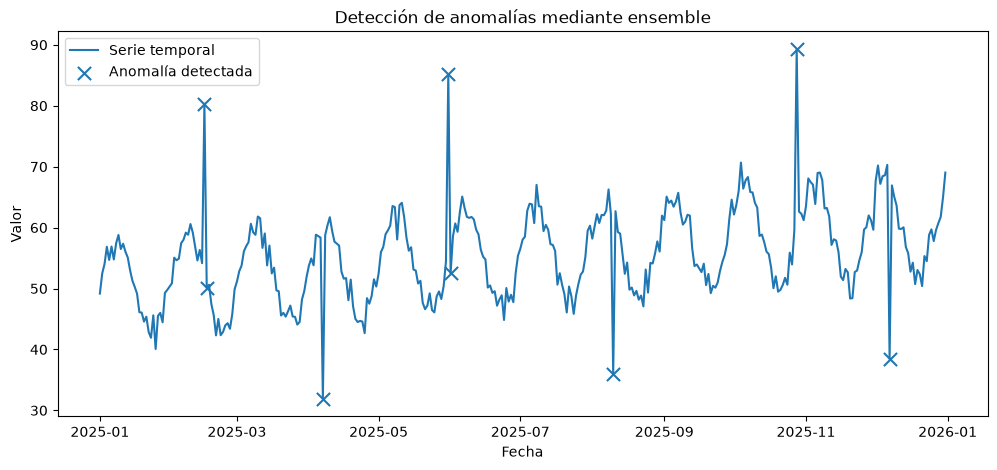

In [22]:
plt.figure(figsize=(12, 5))
plt.plot(datos.index, datos["valor"], label="Serie temporal")

mask = datos["anomalia_ensemble"] == 1
plt.scatter(
    datos.index[mask],
    datos.loc[mask, "valor"],
    marker="x", s=90,
    label="Anomalía detectada"
)

plt.title("Detección de anomalías mediante ensemble")
plt.xlabel("Fecha")
plt.ylabel("Valor")
plt.legend()
plt.show()

## 7. Evaluación

Como en esta simulación conocemos cuáles observaciones fueron alteradas, podemos comparar las detecciones del ensemble contra la referencia real.

In [23]:
from sklearn.metrics import precision_score, recall_score, f1_score

y_true = datos["anomalia_real"]
y_hat = datos["anomalia_ensemble"]

print("Precision:", round(precision_score(y_true, y_hat, zero_division=0), 4))
print("Recall:", round(recall_score(y_true, y_hat, zero_division=0), 4))
print("F1:", round(f1_score(y_true, y_hat, zero_division=0), 4))
print("\nMatriz de confusión:")
print(confusion_matrix(y_true, y_hat))

Precision: 0.75
Recall: 1.0
F1: 0.8571

Matriz de confusión:
[[357   2]
 [  0   6]]


### Interpretación

Cada detector observa la anomalía desde un criterio distinto. KNN utiliza distancia, LOF compara densidades locales e Isolation Forest mide qué tan fácilmente se aísla una observación.

El ensemble normaliza y promedia esas tres evidencias. De esta manera, una observación recibe una puntuación alta cuando varios métodos coinciden en que su comportamiento es poco habitual.

La comparación con las anomalías introducidas permite medir `precision`, `recall` y `F1`. Los valores exactos quedan registrados al ejecutar el notebook.

# Conclusiones generales

1. **PCA / Eigenfaces:** PCA permite reducir una imagen facial de miles de píxeles a un número mucho menor de componentes principales. Las Eigenfaces conservan patrones relevantes de variación y permiten realizar reconocimiento facial sin utilizar redes neuronales.

2. **NMF:** la factorización de matriz no negativa permite representar documentos como combinaciones de temas interpretables. Al comparar esas representaciones mediante similitud de coseno es posible recomendar artículos con contenido temático parecido.

3. **Ensemble de anomalías:** combinar KNN, LOF e Isolation Forest permite integrar criterios de distancia, densidad y aislamiento. La normalización de los scores hace posible promediarlos en una única puntuación de anomalía.

En conjunto, la actividad muestra tres aplicaciones del aprendizaje no supervisado: reducción de dimensionalidad, extracción de temas y detección de observaciones atípicas.